In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: jaspy
#     language: python
#     name: jaspy
# ---

# NB 05 Per-step loss matrix, CVPE and the Model Confidence Set

Input: the `fold_models` artifact of NB04.

* Per-step loss = squared error of E[U1|U2] and E[U2|U1] at that step (CVPE integrand).
* Seeds are averaged **on the loss** within a fold; folds are averaged with `np.nanmean` over the folds that test the step (repeated hold-out: some steps are tested twice, the rest once; the counts are printed in notebook 00). The CVPE of a model is the mean of that series over all usable steps. The spread across folds is descriptive, not a standard error.
* MCS at alpha = 0.10 and 0.05 (the levels the text leads with) and alpha = 0.25 as a sensitivity level (weak evidence; a low alpha retains more models, so 0.25 is the lenient end, not "strict"). Block lengths 1, b/2, b, 2b with b the Politis-White length of the full usable sample (notebook 00); the primary length is the Politis-White length of the loss differentials.
* A larger pool lowers the power of each elimination step and retains more models; this is stated next to the table.
* The last section holds the tail-dependence analysis on a threshold grid; it reads the models and gates above and saves the `tail_grid` artifact for notebook 06.
* Every table of the report is written once, as LaTeX and CSV, in the sections *Tables for the report* and *Tail dependence*; the sections before them only display. The PIT ablation, the per-category MCS, the pair heat map and the fold-level CVPE tables are not part of the report and are not computed.

## At a glance

* **Purpose:** compare the 76 candidates on one common test sample (CVPE), build the Model Confidence Set, and add robustness checks and the tail-dependence grid.
* **Inputs:** `fold_models` and `ces_scores` (NB04). **Outputs:** `comparison_and_mcs`, `ces_comparison`, `tail_grid`, the tables of the report in `Tables 05_comparison_and_mcs/` (LaTeX and CSV) and the figure `chi_grid_empirical.png`.
* **Next step:** continue to NB06 for the remaining figures.
* **Sections:** Load, Pool and exclusions, Per-step loss series, Block-length diagnostic, MCS, Sensitivity, CVPE intervals, Within-fold MCS, Tables for the report, Copula Energy Score, Tail dependence.

## Comparison roadmap: what each step answers

| Step | Rule used in this notebook | Question it answers |
|---|---|---|
| Eligibility | A candidate enters the pool only if its marginal-uniformity statistic D_max is within the gate threshold in every fold and seed; a missing diagnostic counts as a failure | Is the fitted model a valid copula for the whitened pseudo-observations? |
| Common test sample | Per-step loss on the same test steps of the four purged folds; neural models are averaged over their three seeds before comparison | Are all models scored on identical observations? |
| CVPE | Mean over test steps of (u1 - E[U1 given U2])^2 + (u2 - E[U2 given U1])^2, using 100-node Gauss-Legendre quadrature; lower is better | How well does the fitted dependence predict one margin from the other? |
| CES | Not part of this table. When computed it is reported in its own table with its own MCS, never pooled with CVPE | Does the fitted joint dependence distribution match the realised pairs? |
| Block-bootstrap interval | Stationary bootstrap of the loss series with the primary block length | How uncertain is each model's mean CVPE? |
| MCS | Hansen-Lunde-Nason range test with stationary bootstrap, alpha 0.10 and 0.05 reported, alpha 0.25 sensitivity only, block lengths 1, b/2, b, 2b (b = full-sample Politis-White length) | Which models cannot be separated from the best at this confidence level? Survivor status is not proof of equivalence |
| Acar GLRT | Separate panel (when computed). It tests whether dependence varies with divergence within one family | Does dependence change with divergence? It does not rank neural against other models |

## Imports and settings

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"; os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"; os.environ["NUMEXPR_NUM_THREADS"] = "1"
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import plotting_core

from run_support import load_artifact, save_artifact, SMOKE   # SMOKE: production default; override with THESIS_SMOKE (see run_support.py)
import fold_pipeline as FP
import gate_config as GC
import reporting_tables
plotting_core.configure("05_comparison_and_mcs")
reporting_tables.configure("05_comparison_and_mcs")

N_BOOT = 200 if SMOKE else 5000     # MCS bootstrap replicates (5,000 in the thesis)
ALPHAS = (0.10, 0.05, 0.25)   # lead with 0.10 and 0.05; 0.25 is a sensitivity level
B_FULL = int(load_artifact('preprocessing')['b_full'])      # Politis-White length of the full usable sample (data driven)
BLOCK_LENS = tuple(sorted({1, max(1, B_FULL // 2), B_FULL, 2 * B_FULL}))   # sensitivity lengths

## Load

In [3]:
fm = load_artifact("fold_models")
STORE, ARR, FOLDS = fm['store'], fm['arrays'], fm['folds']
PARAM, ACAR, NEURAL, NONPARAM = fm['param'], fm['acar'], fm['neural'], fm['nonparam']
print("artifact built with smoke settings:", fm.get('smoke'))
gt = STORE['gate_table']
print(f"candidates {len(gt)}; with a loss in every fold {len(STORE['models'])}; in pool after gates {int(gt.in_pool.sum())}")
assert len(gt) == GC.N_CANDIDATES, (len(gt), GC.N_CANDIDATES)

artifact built with smoke settings: False
candidates 76; with a loss in every fold 76; in pool after gates 74


## Pool and exclusions

How many of the 49 pairs survive the gates, and which models drop out and why (the gate table lists all 76 candidates; it is written for the report in the section *Tables for the report*). Check this before reading any MCS.

In [4]:
print(gt.groupby('group').in_pool.agg(candidates='size', in_pool='sum').to_string())
print("\nConditional networks: marginal KS is the only numerical validity gate.")
display(gt[['group', 'max_ks', 'threshold', 'in_pool']].sort_values(['group', 'in_pool', 'max_ks'], ascending=[True, False, True]).round(4))

               candidates  in_pool
group                             
Acar                    7        7
Binary                 50       49
Neural                  9        8
Nonparametric           2        2
Unconditional           8        8

Conditional networks: marginal KS is the only numerical validity gate.


,group,max_ks,threshold,in_pool
model,,,,
Acar (continuous): frank,Acar,0.0429,0.0762,True
Acar (continuous): gumbel,Acar,0.0446,0.0762,True
Acar (continuous): joe,Acar,0.0460,0.0762,True
Acar (continuous): student,Acar,0.0463,0.0762,True
Acar (continuous): gaussian,Acar,0.0474,0.0762,True
...,...,...,...,...
Unconditional: t,Unconditional,0.0248,0.0700,True
Unconditional: Gaussian,Unconditional,0.0253,0.0700,True
Unconditional: Gumbel,Unconditional,0.0253,0.0700,True


## Gate disclosure: every candidate's D_max, pool size by threshold, calibration check

The gate threshold is fixed before the runs (reference check D_max <= 0.07, aligned per check type). Every candidate's largest KS distance is reported, together with the pool that would result at 0.05, 0.07 and 0.10. The calibration rule (threshold at least the simulated 99.9th percentile of the null) is checked here.

In [5]:
CAL = GC.check_ks_calibration(raise_on_fail=False)
print(f"reference threshold {GC.KS_D_MAX}; simulated 99.9th percentile of the reference null {CAL['ref_null_q999']:.4f}; rule satisfied: {CAL['ok']}")
if not CAL['ok']:
    print(f"WARNING: raise KS_D_MAX to {CAL['recommended']:.3f} (pre-declared rule) before the production run")
POOL_SIZES = FP.pool_size_table(gt)
reporting_tables.show_table(POOL_SIZES, 'gate_pool_sizes', caption='Pool size by group at each reference threshold.')
NEURAL_ROWS = gt[(gt.group == 'Neural') | gt.index.isin([FP.UNCOND_CODINE, FP.SPLIT_CODINE])]
n_neural_in = int(NEURAL_ROWS.in_pool.sum())
print(f"\nNeural candidates (12) passing the gate: {n_neural_in}")
if n_neural_in < 2:
    print("FALLBACK (pre-declared): fewer than two neural candidates pass. Report the best neural candidate of each family "
          "below, flagged as failing the gate, and say so in the text; the MCS pool itself is not changed.")
    display(NEURAL_ROWS[['max_ks', 'threshold', 'in_pool']])

reference threshold 0.07; simulated 99.9th percentile of the reference null 0.0654; rule satisfied: True


**gate pool sizes**

,D_max <= 0.05,D_max <= 0.07,D_max <= 0.10,candidates
group,,,,
Acar,7,7,7,7
Binary,49,49,50,50
Neural,3,8,8,9
Nonparametric,2,2,2,2
Unconditional,7,8,8,8
Total,68,74,75,76



Neural candidates (12) passing the gate: 9


## Per-step loss series (the MCS input)

In [6]:
L, MODELS = FP.per_step_loss(STORE, only_pool=True)
GROUP = {m: STORE['group'][m] for m in MODELS}
print("per-step loss matrix:", L.shape, "(steps x models in pool)")
cvpe = pd.Series(L.mean(axis=0), index=MODELS, name='CVPE').sort_values()

per-step loss matrix: (2884, 74) (steps x models in pool)


## Block-length diagnostic (decides the primary MCS block length)

A Politis-White block length estimated on the loss differentials of the best model against the others (median across pairs). Data-driven rule: the estimate alone, no floor and no fixed length anywhere. If block length 1 gives the same confidence sets as the longer blocks, say so in the text; if not, that is the evidence for the blocks.

In [7]:
dd = FP.differential_diagnostics(L, MODELS, nlags=250)
print("best model:", dd['best'], "| median Politis-White block length on the differentials:", dd['block_length_median'])
PRIMARY_BLOCK = int(max(1, np.ceil(dd['block_length_median']))) if np.isfinite(dd['block_length_median']) else int(B_FULL)
print("primary block length (Politis-White on the loss differentials):", PRIMARY_BLOCK, "| full-sample b:", B_FULL)

best model: Acar (continuous): gumbel180 | median Politis-White block length on the differentials: 3.0
primary block length (Politis-White on the loss differentials): 3 | full-sample b: 97


## MCS at alpha 0.10, 0.05, 0.25 and block lengths 1, b/2, b, 2b

In [8]:
BL_ALL = tuple(sorted(set(BLOCK_LENS) | {PRIMARY_BLOCK}))
MCS_TAB, MCS_RAW = FP.mcs_table(L, MODELS, block_lens=BL_ALL, alphas=ALPHAS, n_boot=N_BOOT, seed=0)
pb = PRIMARY_BLOCK
main = pd.DataFrame({'group': [GROUP[m] for m in MODELS], 'CVPE': cvpe.reindex(MODELS).values,
                     'p-value': MCS_TAB[f'p@b{pb}'],
                     'in MCS (alpha=0.10)': MCS_TAB[f'in@b{pb}@a0.1'],
                     'in MCS (alpha=0.05)': MCS_TAB[f'in@b{pb}@a0.05'],
                     'in MCS (alpha=0.25, sensitivity)': MCS_TAB[f'in@b{pb}@a0.25']}, index=MODELS).sort_values('CVPE')
print(f"primary block length {pb}; pool {len(MODELS)} models")
display(main.head(20).round(5))
print("\nSurvivors per alpha:", {a: int(MCS_TAB[f'in@b{pb}@a{a:g}'].sum()) for a in ALPHAS})
print("\nSurvivor counts across block lengths (rows: alpha, columns: block length):")
display(pd.DataFrame({bl: {a: int(MCS_TAB[f'in@b{bl}@a{a:g}'].sum()) for a in ALPHAS} for bl in BL_ALL}).rename_axis('alpha'))

primary block length 3; pool 74 models


,group,CVPE,p-value,in MCS (alpha=0.10),in MCS (alpha=0.05),"in MCS (alpha=0.25, sensitivity)"
Acar (continuous): gumbel180,Acar,0.16418,1.0000,True,True,True
Acar (continuous): clayton,Acar,0.16440,0.6666,True,True,True
Acar (continuous): gumbel,Acar,0.16474,0.6666,True,True,True
Acar (continuous): frank,Acar,0.16475,0.6666,True,True,True
Acar (continuous): student,Acar,0.16480,0.6666,True,True,True
C-CODINE (FiLM),Neural,0.16486,0.6666,True,True,True
Acar (continuous): gaussian,Acar,0.16489,0.0112,False,False,False
Acar (continuous): joe,Acar,0.16498,0.0112,False,False,False
Nonparametric: ECBC (Lu and Ghosh 2024),Nonparametric,0.16512,0.4536,True,True,True
Unconditional: Gumbel,Unconditional,0.16513,0.0112,False,False,False



Survivors per alpha: {0.1: 7, 0.05: 7, 0.25: 7}

Survivor counts across block lengths (rows: alpha, columns: block length):


,1,3,48,97,194
alpha,,,,,
0.10,8,7,7,6,6
0.05,8,7,22,19,6
0.25,8,7,7,6,6


### Sensitivity: MCS under the alternative gate thresholds

Same loss series, same block length, pools defined by D_max <= 0.10 (loose) and <= 0.05 (strict). The primary MCS uses the pool at 0.07.

In [9]:
SENS_MCS = {}
for _d in (GC.KS_D_MAX_LOOSE, GC.KS_D_MAX_STRICT):
    _pool = [m for m in FP.pool_at_threshold(gt, _d) if m in STORE['models']]
    if len(_pool) < 2:
        print(f"D_max <= {_d:.2f}: pool of {len(_pool)} models, MCS not run"); continue
    _Ls, _ms = FP.per_step_loss(STORE, only_pool=False, models=_pool)
    _tab, _ = FP.mcs_table(_Ls, _ms, block_lens=(pb,), alphas=(0.10, 0.05), n_boot=N_BOOT, seed=0)
    SENS_MCS[_d] = _tab
    print(f"D_max <= {_d:.2f}: pool {len(_ms)}; survivors alpha 0.10: {int(_tab[f'in@b{pb}@a0.1'].sum())}, alpha 0.05: {int(_tab[f'in@b{pb}@a0.05'].sum())}")

D_max <= 0.10: pool 75; survivors alpha 0.10: 7, alpha 0.05: 7


D_max <= 0.05: pool 68; survivors alpha 0.10: 7, alpha 0.05: 7


### Sensitivity of the survivor set to the bootstrap seed (0, 1, 2)

In [10]:
stab = FP.mcs_seed_stability(L, MODELS, pb, alphas=ALPHAS, seeds=(0, 1, 2), n_boot=N_BOOT)
stab['n'] = stab.survivors.map(len)
base = stab[stab.seed == 0].set_index('alpha').survivors.map(set)
stab['same_as_seed0'] = [set(s) == base[a] for s, a in zip(stab.survivors, stab.alpha)]
display(stab[['seed', 'alpha', 'n', 'same_as_seed0']])

,seed,alpha,n,same_as_seed0
0,0,0.10,7,True
1,0,0.05,7,True
2,0,0.25,7,True
3,1,0.10,8,False
4,1,0.05,8,False
5,1,0.25,8,False
6,2,0.10,8,False
7,2,0.05,8,False
8,2,0.25,8,False


## Robustness: MCS separately for each fold

Every fold scores a test step on its own conditional PIT, so the pooled loss series averages log scores on different scales (always the same folds for all models; the assertion in `per_step_loss` checks this). As a robustness check the MCS is also run on each fold's own test window: one PIT scale, nothing averaged, no stitching. This is possible for the folds whose test steps form one contiguous stretch (A1, A2, B1). B2 tests two separated outer quarters and is skipped, because joining them would put an artificial junction into the bootstrap. Agreement with the pooled MCS supports the pooled result.

In [11]:
FOLD_MCS, FOLD_SKIPPED = {}, []
for _f in FOLDS:
    try:
        _Lf, _msf, _pos = FP.per_fold_loss(STORE, _f, models=MODELS, only_pool=False)
    except ValueError as _e:
        FOLD_SKIPPED.append(_f); print(f"fold {_f} skipped: {_e}"); continue
    _tab, _ = FP.mcs_table(_Lf, _msf, block_lens=(pb,), alphas=(0.10, 0.05), n_boot=N_BOOT, seed=0)
    FOLD_MCS[_f] = _tab
    print(f"fold {_f}: {len(_Lf)} test steps; survivors alpha 0.10: {int(_tab[f'in@b{pb}@a0.1'].sum())}, alpha 0.05: {int(_tab[f'in@b{pb}@a0.05'].sum())}")
BY_FOLD = pd.DataFrame({'group': [GROUP[m] for m in MODELS], 'p pooled': MCS_TAB[f'p@b{pb}'], 'in pooled': MCS_TAB[f'in@b{pb}@a0.1']}, index=MODELS)
for _f, _tab in FOLD_MCS.items():
    BY_FOLD[f'p {_f}'] = _tab[f'p@b{pb}']; BY_FOLD[f'in {_f}'] = _tab[f'in@b{pb}@a0.1']
_flags = [c for c in BY_FOLD.columns if c.startswith('in ')]
_sv = {c: set(BY_FOLD.index[BY_FOLD[c].astype(bool)]) for c in _flags}
def _jac(a, b):
    """Jaccard index of two sets (0 if both are empty).

    Parameters:
    a (set): First set.
    b (set): Second set.

    Returns:
    float: Size of the intersection divided by the size of the union.
    """
    return len(a & b) / max(len(a | b), 1)
print("survivors at alpha 0.10:", {c: len(v) for c, v in _sv.items()})
print("Jaccard with the pooled set:", {c: round(_jac(_sv['in pooled'], v), 2) for c, v in _sv.items() if c != 'in pooled'})
print("pooled survivors excluded in at least one fold:", sorted(_sv['in pooled'] - set.intersection(*_sv.values())))
_show = BY_FOLD[BY_FOLD[_flags].any(axis=1)].sort_values('p pooled', ascending=False)
_t = _show.drop(columns='group').copy(); _t.index.name = 'model'
for _c in _flags: _t[_c] = _t[_c].astype(bool)           # shade_bool only colours real booleans
display(_show.round(3))
reporting_tables.df_to_latex(_t, 'mcs_by_fold.tex',
    caption=(r'MCS $p$-values and membership at $\alpha=0.10$, pooled over all four folds and separately on the test window of each fold with a contiguous test set (A1, A2, B1). '
             r'Only models that survive in at least one analysis are shown. Green: model in the set; red: model eliminated.'),
    label='tab:mcs_by_fold', digits=3, longtable=True, shade_bool=True, compact=True,
    col_format=r'>{\raggedright\arraybackslash}p{0.38\textwidth}' + r'r>{\centering\arraybackslash}p{0.9cm}' * len(_flags),
    headers=['model'] + sum([[r'$p$ ' + _c[3:], 'in'] for _c in _flags], []),
    short_caption='MCS by fold, pooled and per test window')

fold A1: 1393 test steps; survivors alpha 0.10: 12, alpha 0.05: 24


fold A2: 1394 test steps; survivors alpha 0.10: 3, alpha 0.05: 3


fold B1: 1345 test steps; survivors alpha 0.10: 43, alpha 0.05: 64
fold B2 skipped: fold B2: the test steps are not one contiguous stretch
survivors at alpha 0.10: {'in pooled': 7, 'in A1': 12, 'in A2': 3, 'in B1': 43}
Jaccard with the pooled set: {'in A1': 0.36, 'in A2': 0.43, 'in B1': 0.16}
pooled survivors excluded in at least one fold: ['Acar (continuous): clayton', 'Acar (continuous): frank', 'Acar (continuous): gumbel180', 'Acar (continuous): student', 'C-CODINE (FiLM)', 'Nonparametric: ECBC (Lu and Ghosh 2024)']


,group,p pooled,in pooled,p A1,in A1,p A2,in A2,p B1,in B1
Acar (continuous): gumbel180,Acar,1.000,True,1.000,True,0.014,False,1.000,True
Acar (continuous): gumbel,Acar,0.667,True,0.347,True,1.000,True,0.889,True
Acar (continuous): frank,Acar,0.667,True,0.099,False,0.980,True,0.752,True
Acar (continuous): clayton,Acar,0.667,True,0.523,True,0.009,False,1.000,True
C-CODINE (FiLM),Neural,0.667,True,0.523,True,0.014,False,1.000,True
Acar (continuous): student,Acar,0.667,True,0.073,False,0.980,True,0.889,True
Nonparametric: ECBC (Lu and Ghosh 2024),Nonparametric,0.454,True,0.347,True,0.026,False,0.752,True
Unconditional: Gumbel (180°),Unconditional,0.011,False,0.017,False,0.009,False,0.752,True
Unconditional: Gaussian,Unconditional,0.011,False,0.007,False,0.005,False,1.000,True
Unconditional: t,Unconditional,0.011,False,0.007,False,0.009,False,1.000,True


'\\begingroup\\footnotesize\\setlength{\\tabcolsep}{3pt}\n\\begin{longtable}{>{\\raggedright\\arraybackslash}p{0.38\\textwidth}r>{\\centering\\arraybackslash}p{0.9cm}r>{\\centering\\arraybackslash}p{0.9cm}r>{\\centering\\arraybackslash}p{0.9cm}r>{\\centering\\arraybackslash}p{0.9cm}}\n\\caption[MCS by fold, pooled and per test window]{MCS $p$-values and membership at $\\alpha=0.10$, pooled over all four folds and separately on the test window of each fold with a contiguous test set (A1, A2, B1). Only models that survive in at least one analysis are shown. Green: model in the set; red: model eliminated.}\\label{tab:mcs_by_fold}\\\\\n\\toprule\nmodel & $p$ pooled & in & $p$ A1 & in & $p$ A2 & in & $p$ B1 & in \\\\\n\\midrule\\endfirsthead\n\\toprule\nmodel & $p$ pooled & in & $p$ A1 & in & $p$ A2 & in & $p$ B1 & in \\\\\n\\midrule\\endhead\n\\bottomrule\\endfoot\nAcar (continuous): gumbel180 & 1.000 & \\cellcolor{green!20}yes & 1.000 & \\cellcolor{green!20}yes & 0.014 & \\cellcolor{red!2

## CVPE with block-bootstrap CIs on the averaged series (not a single fold)

In [12]:
from model_evaluation import cvpe_ci_all_models
ci = cvpe_ci_all_models(L, MODELS, b=pb, n_boot=min(N_BOOT, 2000), show_progress=False)
ci['group'] = [GROUP[m] for m in ci.index]
display(ci.sort_values('mean_loss').head(15).round(5))

,n,mean_loss,ci_lo,ci_hi,group
variant,,,,,
Acar (continuous): gumbel180,2884,0.16418,0.15985,0.16838,Acar
Acar (continuous): clayton,2884,0.16440,0.16003,0.16851,Acar
Acar (continuous): gumbel,2884,0.16474,0.16043,0.16886,Acar
Acar (continuous): frank,2884,0.16475,0.16038,0.16888,Acar
Acar (continuous): student,2884,0.16480,0.16038,0.16900,Acar
C-CODINE (FiLM),2884,0.16486,0.16064,0.16896,Neural
Acar (continuous): gaussian,2884,0.16489,0.16048,0.16911,Acar
Acar (continuous): joe,2884,0.16498,0.16076,0.16900,Acar
Nonparametric: ECBC (Lu and Ghosh 2024),2884,0.16512,0.16080,0.16931,Nonparametric


## Joint top-20% CVPE (descriptive, no CI)

The region is defined per fold from that fold's test pseudo-observations (the PIT is refit per fold); folds are combined with fold-share weights.

In [13]:
top20 = FP.joint_top_cvpe(STORE, ARR, models=MODELS, q=0.80)
print("steps in the region per fold:", top20.attrs['n_per_fold'])
cmp = pd.DataFrame({'CVPE (pooled)': cvpe, 'CVPE (joint top-20%, fold-share weighted)': top20['weighted']}).sort_values('CVPE (joint top-20%, fold-share weighted)')
display(cmp.head(15).round(5))

steps in the region per fold: {'A1': 58, 'A2': 76, 'B1': 69, 'B2': 70}


,CVPE (pooled),"CVPE (joint top-20%, fold-share weighted)"
Acar (continuous): gumbel,0.16474,0.25749
Acar (continuous): student,0.16480,0.26053
Acar (continuous): frank,0.16475,0.26075
Acar (continuous): gaussian,0.16489,0.26251
Nonparametric: Gijbels et al. (2011),0.17122,0.26350
Unconditional: Gumbel,0.16513,0.26399
Acar (continuous): joe,0.16498,0.26420
Nonparametric: ECBC (Lu and Ghosh 2024),0.16512,0.26810
"C-CopFlow (FiLM, spline coupling)",0.16618,0.26914
Divergence split: Gumbel (low) / Gumbel (high),0.16572,0.27024


## Save

In [14]:
save_artifact("comparison_and_mcs",
              model_names=MODELS, loss_matrix=L, groups=GROUP, cvpe=cvpe, primary_block=pb, block_lens=BL_ALL,
              alphas=ALPHAS, mcs_table=MCS_TAB, main_table=main, mcs_raw=MCS_RAW, seed_stability=stab,
              cvpe_ci=ci, top20=top20, top20_compare=cmp, gate_table=gt, selected_pairs=STORE['selected_pair'],
              diff_diagnostics={k: v for k, v in dd.items() if k != 'acf_all'}, n_boot=N_BOOT, smoke=SMOKE)
print("saved comparison_and_mcs")

saved comparison_and_mcs


## Tables for the report

Written from the saved `comparison_and_mcs` and `fold_models` artifacts; nothing is recomputed and nothing is displayed (the tables were shown above). Every table is written as LaTeX and CSV. MCS wording: results lead with alpha = 0.10 and 0.05; alpha = 0.25 is a sensitivity level read as weak evidence. Files go to the folder `Tables 05_comparison_and_mcs`.

In [15]:
import reporting_tables as RT
cmp_art = load_artifact("comparison_and_mcs"); fm = load_artifact("fold_models")
main, gt = cmp_art['main_table'], cmp_art['gate_table']
PB = cmp_art['primary_block']; FOLDS = fm['folds']
print("primary block", PB, "| smoke artifact:", cmp_art.get('smoke'), fm.get('smoke'))

primary block 3 | smoke artifact: False False


## MCS tables (top 20 with the CVPE interval, all models in the pool) and group summary

In [16]:
RT.mcs_fold_design_table(main, PB, filename='mcs_main_top20.tex', longtable=False, top=20, label='tab:mcs_top20', ci=cmp_art['cvpe_ci'])
RT.mcs_fold_design_table(main, PB, filename='mcs_appendix_longtable.tex', longtable=True, label='tab:mcs_appendix')
RT.mcs_group_summary_table(main, gt)

'\\begin{table}[htbp]\\centering\\small\n\\caption{Candidates, gate survivors, best model by CVPE and MCS survivors per model group. Inclusion is reported at $\\alpha=0.10$ and $\\alpha=0.05$, which are the levels the conclusions rest on. $\\alpha=0.25$ is a sensitivity level only: the MCS procedure eliminates a model when its $p$-value falls below $\\alpha$, so a larger $\\alpha$ removes more models on weaker evidence and is read as weak evidence, not as a stricter test.}\\label{tab:mcs_group_summary}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{llrp{4.2cm}rrrr}\n\\toprule\ngroup & candidates & in pool & best model & best CVPE & MCS 0.10 & MCS 0.05 & MCS 0.25 \\\\\n\\midrule\nAcar & 7 & 7 & Acar (continuous): gumbel180 & 0.1642 & 5 & 5 & 5 \\\\\nBinary & 50 & 49 & Divergence split: Gumbel (low) / Joe (high) & 0.1657 & 0 & 0 & 0 \\\\\nNeural & 9 & 8 & C-CODINE (FiLM) & 0.1649 & 1 & 1 & 1 \\\\\nNonparametric & 2 & 2 & Nonparametric: ECBC (L

## Gate table and excluded models

In [17]:
g = gt.copy(); g.index.name = 'model'
g['in_pool'] = g['in_pool'].astype(bool)          # shade_bool only colours real booleans
cols = [c for c in ('group', 'max_ks', 'threshold', 'in_pool') if c in g.columns]
RT.df_to_latex(g[cols].sort_values(['group', 'in_pool'], ascending=[True, False]), 'gate_table_longtable.tex',
               r'Marginal-uniformity screening for all 76 candidates. The threshold is $D_{\max}\leq 0.07$ for a check with two KS tests (one simulated copula, two margins), calibrated to the 99.9th percentile of the simulated null, and is raised by the simulated null margin for the 14-test checks (seven covariate percentiles, two margins; about 0.076 exact sampler, 0.078 grid sampler); the column threshold gives the value used. $D_{\max}$ is the maximum KS distance of independently generated copula margins over the required folds, seeds, regimes and covariate values. Missing diagnostics fail the screen. Passing does not establish joint goodness-of-fit. Green: candidate enters the pool; red: candidate excluded.',
               'tab:gates', longtable=True,
               col_format=r'>{\raggedright\arraybackslash}p{0.46\textwidth}lrr>{\centering\arraybackslash}p{1.1cm}',
               headers=['model', 'group', 'max KS', 'threshold', 'in pool'],
               shade_bool=True, compact=True,
               short_caption='Marginal-uniformity screening, all 76 candidates')

'\\begingroup\\footnotesize\\setlength{\\tabcolsep}{3pt}\n\\begin{longtable}{>{\\raggedright\\arraybackslash}p{0.46\\textwidth}lrr>{\\centering\\arraybackslash}p{1.1cm}}\n\\caption[Marginal-uniformity screening, all 76 candidates]{Marginal-uniformity screening for all 76 candidates. The threshold is $D_{\\max}\\leq 0.07$ for a check with two KS tests (one simulated copula, two margins), calibrated to the 99.9th percentile of the simulated null, and is raised by the simulated null margin for the 14-test checks (seven covariate percentiles, two margins; about 0.076 exact sampler, 0.078 grid sampler); the column threshold gives the value used. $D_{\\max}$ is the maximum KS distance of independently generated copula margins over the required folds, seeds, regimes and covariate values. Missing diagnostics fail the screen. Passing does not establish joint goodness-of-fit. Green: candidate enters the pool; red: candidate excluded.}\\label{tab:gates}\\\\\n\\toprule\nmodel & group & max KS & th

## Block-length and alpha sensitivity of the survivor counts

In [18]:
bl = cmp_art['block_lens']; mt = cmp_art['mcs_table']
sens = pd.DataFrame({f"b={b}": {f"alpha={a}": int(mt[f'in@b{b}@a{a}'].sum()) for a in ('0.1', '0.05', '0.25')} for b in bl})
sens.index.name = 'level'
RT.df_to_latex(sens, 'mcs_block_alpha_sensitivity.tex', 'Number of models in the MCS by bootstrap block length and significance level. ' + RT.MCS_CAPTION_ALPHA,
               'tab:mcs_sens', digits=0, col_format='l' + 'r' * len(bl))

'\\begin{table}[htbp]\\centering\\small\n\\caption{Number of models in the MCS by bootstrap block length and significance level. Inclusion is reported at $\\alpha=0.10$ and $\\alpha=0.05$, which are the levels the conclusions rest on. $\\alpha=0.25$ is a sensitivity level only: the MCS procedure eliminates a model when its $p$-value falls below $\\alpha$, so a larger $\\alpha$ removes more models on weaker evidence and is read as weak evidence, not as a stricter test.}\\label{tab:mcs_sens}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{lrrrrr}\n\\toprule\nlevel & b=1 & b=3 & b=48 & b=97 & b=194 \\\\\n\\midrule\nalpha=0.1 & 8 & 7 & 7 & 6 & 6 \\\\\nalpha=0.05 & 8 & 7 & 22 & 19 & 6 \\\\\nalpha=0.25 & 8 & 7 & 7 & 6 & 6 \\\\\n\\bottomrule\n\\end{tabular}}\\end{table}\n'

## Seed stability of the MCS

In [19]:
st = cmp_art['seed_stability'].copy(); st['survivors'] = st.survivors.map(lambda s: len(s))
RT.df_to_latex(st[['seed', 'alpha', 'n', 'same_as_seed0']] if 'n' in st else st[['seed', 'alpha', 'survivors']], 'mcs_seed_stability.tex',
               'MCS survivor counts under different bootstrap seeds at the primary block length.', 'tab:mcs_seed', index=False, digits=2)

'\\begin{table}[htbp]\\centering\\small\n\\caption{MCS survivor counts under different bootstrap seeds at the primary block length.}\\label{tab:mcs_seed}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{lrrr}\n\\toprule\nseed & alpha & n & same\\_as\\_seed0 \\\\\n\\midrule\n0 & 0.10 & 7 & yes \\\\\n0 & 0.05 & 7 & yes \\\\\n0 & 0.25 & 7 & yes \\\\\n1 & 0.10 & 8 & no \\\\\n1 & 0.05 & 8 & no \\\\\n1 & 0.25 & 8 & no \\\\\n2 & 0.10 & 8 & no \\\\\n2 & 0.05 & 8 & no \\\\\n2 & 0.25 & 8 & no \\\\\n\\bottomrule\n\\end{tabular}}\\end{table}\n'

## CVPE intervals of the unconditional and binary-split models, and the joint top-20% comparison

In [20]:
ci = cmp_art['cvpe_ci'].copy(); ci.index.name = 'model'
listing = ci[ci.index.str.startswith(('Unconditional: ', 'Divergence split: '))]
RT.df_to_latex(listing[['n', 'mean_loss', 'ci_lo', 'ci_hi']], 'cvpe_ci_unconditional_binary.tex',
               'CVPE with stationary-bootstrap intervals, unconditional and binary-split models (listing order; the continuous Acar curves are not in this table).',
               'tab:cvpe_ci_listing', longtable=True, digits=5, compact=True,
               col_format=r'>{\raggedright\arraybackslash}p{0.52\textwidth}rrrr',
               headers=['model', '$n$', 'CVPE', 'CI low', 'CI high'],
               short_caption='CVPE with stationary-bootstrap intervals, unconditional and binary-split models')
top = cmp_art['top20_compare'].copy(); top.index.name = 'model'
RT.df_to_latex(top.head(20), 'joint_top20_cvpe_fold.tex',
               r'CVPE pooled versus restricted to each fold joint top-20\% region (fold-share weighted; descriptive).', 'tab:top20',
               digits=5, compact=True, col_format=r'>{\raggedright\arraybackslash}p{0.55\textwidth}rr',
               headers=['model', 'CVPE (pooled)', r'CVPE (top-20\%)'],
               short_caption=r'CVPE pooled and in the joint top-20\% region')

'\\begin{table}[htbp]\\centering\\footnotesize\\setlength{\\tabcolsep}{3pt}\n\\caption[CVPE pooled and in the joint top-20\\% region]{CVPE pooled versus restricted to each fold joint top-20\\% region (fold-share weighted; descriptive).}\\label{tab:top20}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{>{\\raggedright\\arraybackslash}p{0.55\\textwidth}rr}\n\\toprule\nmodel & CVPE (pooled) & CVPE (top-20\\%) \\\\\n\\midrule\nAcar (continuous): gumbel & 0.16474 & 0.25749 \\\\\nAcar (continuous): student & 0.16480 & 0.26053 \\\\\nAcar (continuous): frank & 0.16475 & 0.26075 \\\\\nAcar (continuous): gaussian & 0.16489 & 0.26251 \\\\\nNonparametric: Gijbels et al. (2011) & 0.17122 & 0.26350 \\\\\nUnconditional: Gumbel & 0.16513 & 0.26399 \\\\\nAcar (continuous): joe & 0.16498 & 0.26420 \\\\\nNonparametric: ECBC (Lu and Ghosh 2024) & 0.16512 & 0.26810 \\\\\nC-CopFlow (FiLM, spline coupling) & 0.16618 & 0.26914 \\\\\nDivergence split: Gumbel (low) / 

## Copula Energy Score comparison (separate from CVPE; never pooled)

Own table, own MCS on the CES series, same fold design, same test steps, same stationary bootstrap and block lengths. Models without a CES are listed with the reason. The CES MCS is run only on pool models that have a CES in every fold; networks scored from fewer than three seeds are flagged. The score is deterministic quadrature (no Monte Carlo error); its numerical settings are shown. Survivor status is not proof of equivalence.

In [21]:
_ces = load_artifact("ces_scores")
if not _ces:
    print("CES not computed: run the 'Copula Energy Score' section of notebook 04 first (needs the stored networks).")
else:
    CS = _ces['store_raw']
    _ms = [m for m in CS['models'] if CS['in_pool'].get(m)]
    _L = np.nanmean(CS['tensor'][:, [CS['models'].index(m) for m in _ms], :], axis=2)
    if not np.isfinite(_L).all():
        print("CES series has NaN steps for some pool models: those models are excluded from the CES MCS")
        _keep = np.isfinite(_L).all(axis=0); _ms = [m for m, k in zip(_ms, _keep) if k]; _L = _L[:, _keep]
    _tab, _ = FP.mcs_table(_L, _ms, block_lens=(pb,), alphas=ALPHAS, n_boot=N_BOOT, seed=0)
    CES_MAIN = _ces['table'].loc[_ms].copy()
    CES_MAIN['p-value'] = _tab[f'p@b{pb}']
    for a in ALPHAS:
        CES_MAIN[f'in CES-MCS (alpha={a:g})'] = _tab[f'in@b{pb}@a{a:g}']
    CES_MAIN = CES_MAIN.sort_values('ces')
    display(CES_MAIN.head(20).round(5))
    print(f"pool models with a CES: {len(_ms)} of {int(gt.in_pool.sum())}; independence CES {_ces['table'].attrs['independence_ces']:.5f}; "
          f"estimator: {_ces['table'].attrs['estimator']}")
    print("survivors:", {a: int(_tab[f'in@b{pb}@a{a:g}'].sum()) for a in ALPHAS})
    _few = CES_MAIN[CES_MAIN.seeds_used.fillna(3) < 3]
    if len(_few):
        print(f"WARNING: {len(_few)} neural models are scored from fewer than 3 seeds (weights of the other seeds were not stored): {list(_few.index)[:4]} ...")
    print("models without a CES:", {m: r for m, r in list(CS['no_ces'].items())[:6]}, "..." if len(CS['no_ces']) > 6 else "")
    save_artifact("ces_comparison", main_table=CES_MAIN, mcs_table=_tab, primary_block=pb, alphas=ALPHAS, n_boot=N_BOOT, smoke=SMOKE)

,group,in_pool,ces,vs_independence,seeds_used,ces_calibrated,p-value,in CES-MCS (alpha=0.1),in CES-MCS (alpha=0.05),in CES-MCS (alpha=0.25)
model,,,,,,,,,,
Acar (continuous): gumbel180,Acar,True,0.26002,0.00021,NaN,0.26002,1.0000,True,True,True
Acar (continuous): clayton,Acar,True,0.26003,0.00020,NaN,0.26003,0.5658,True,True,True
Nonparametric: ECBC (Lu and Ghosh 2024),Nonparametric,True,0.26008,0.00014,NaN,0.26008,0.2332,True,True,False
Acar (continuous): gumbel,Acar,True,0.26009,0.00013,NaN,0.26009,0.2332,True,True,False
Acar (continuous): frank,Acar,True,0.26010,0.00013,NaN,0.26010,0.2332,True,True,False
Acar (continuous): gaussian,Acar,True,0.26010,0.00012,NaN,0.26010,0.1630,True,True,False
Acar (continuous): student,Acar,True,0.26011,0.00012,NaN,0.26011,0.1630,True,True,False
Acar (continuous): joe,Acar,True,0.26011,0.00012,NaN,0.26011,0.1630,True,True,False
Unconditional: Gumbel,Unconditional,True,0.26014,0.00009,NaN,0.26014,0.0988,False,True,False


pool models with a CES: 74 of 74; independence CES 0.26023; estimator: deterministic quadrature K=64, covariate grid G=81 (no Monte Carlo)
survivors: {0.1: 9, 0.05: 11, 0.25: 2}
models without a CES: {} 


### CES table for the report (written only when the CES comparison above was computed)

In [22]:
_cc = load_artifact('ces_comparison')
if not _cc:
    print("CES comparison not computed: no ces_table.tex written. (Does not affect the other tables.)")
else:
    _t = _cc['main_table'].head(20).copy(); _t.index.name = 'model'
    _cols = [c for c in ('group', 'ces', 'vs_independence', 'seeds_used', 'p-value', 'in CES-MCS (alpha=0.1)', 'in CES-MCS (alpha=0.05)') if c in _t.columns]
    RT.df_to_latex(_t[_cols], 'ces_table.tex', 'Copula Energy Score (raw joint score, lower is better), top 20 models with CES-MCS membership. Independence reference in the text.', 'tab:ces', digits=5)
    print("written ces_table.tex")

written ces_table.tex


## Tail dependence on a threshold grid

This section needs only the objects above. The coefficient chi-hat(q) = P(U2 > q | U1 > q) at q = 0.95 is a finite-threshold co-exceedance probability, not the asymptotic chi = lim chi(q). Under independence chi(q) = 1 - q (0.05 at q = 0.95). Student-t and Clayton impose a non-zero limit by their form; Gaussian and Frank have lambda = 0 yet give chi(0.95) > 0.05 for any positive dependence. So q and the family assumption drive the conclusion; this notebook shows chi-hat(q) and Coles' chi-bar(q) on q in {0.80, 0.85, 0.90, 0.95} with the number of joint exceedances behind every cell, block-bootstrap bands (mean block length b, the full-sample Politis-White length; regime-aware for regime cells, at least 200 replicates), and the model-implied curve chi_m(q) = P_m(U1>q, U2>q)/(1-q) against it.

Descriptive tables use the full-sample kernel-conditional u (labelled descriptive, **not used for selection**) and the fold-training version as a stability check. Neither selects families.

In [23]:
import model_diagnostics as TG
N_BOOT_TAIL = 200 if SMOKE else 500   # >= 200 for reported bands
TAIL_BLOCK = B_FULL   # full-sample Politis-White length
QS = TG.Q_THRESHOLDS

## Empirical chi-hat(q), chi-bar(q) with counts and bands

(a) Full-sample kernel-conditional u (descriptive). `n_joint` is the number of joint exceedances; `expected_joint_indep` is what independence would give.

In [24]:
f0 = load_artifact(f"preprocessing_fold_{FOLDS[0]}")
u1_full, u2_full, high_full = TG.full_sample_regime_u(f0['precip_aligned'], f0['wind_aligned'], f0['div_aligned'], h=float(f0['kernel_h']))
GRID_FULL = TG.chi_grid_with_bands(u1_full, u2_full, high_full, QS, b=TAIL_BLOCK, n_boot=N_BOOT_TAIL)
cols = ['group', 'tail', 'q', 'n', 'n_joint', 'expected_joint_indep', 'chi', 'chi_lo', 'chi_hi', 'independence', 'chibar', 'chibar_lo', 'chibar_hi']
display(GRID_FULL[cols].round(3))

# LaTeX version for the appendix: 6 columns instead of 13 (estimate and band in one cell; counts as observed / expected)
def _f(x):
    """Format a number with three decimals and a typeset minus sign.

    Parameters:
    x (float): Number to format.

    Returns:
    str: The LaTeX-ready text.
    """
    return f'{x:.3f}'.replace('-', '$-$')
_c = GRID_FULL
_t = pd.DataFrame({'regime': _c.group, 'tail': _c['tail'], '$q$': _c.q.map(lambda x: f'{x:.2f}'),
                   'joint exceed. (obs / exp)': [f'{int(a)} / {b:.1f}' for a, b in zip(_c.n_joint, _c.expected_joint_indep)],
                   r'$\hat\chi(q)$ [95\% band]': [f'{_f(a)} [{_f(b)}, {_f(d)}]' for a, b, d in zip(_c.chi, _c.chi_lo, _c.chi_hi)],
                   r'$\bar\chi(q)$ [95\% band]': [f'{_f(a)} [{_f(b)}, {_f(d)}]' for a, b, d in zip(_c.chibar, _c.chibar_lo, _c.chibar_hi)]})
_n = GRID_FULL.groupby('group')['n'].first()
def _tex_n(n):
    """Format an integer with a thousands separator that LaTeX typesets without extra space.

    Parameters:
    n (int): Number to format.

    Returns:
    str: The text, for example '2{,}884'.
    """
    return f'{int(n):,}'.replace(',', '{,}')
_n_regimes = (f'${_tex_n(_n["low"])}$ in each divergence regime' if _n['low'] == _n['high']
              else f'${_tex_n(_n["low"])}$ low-divergence and ${_tex_n(_n["high"])}$ high-divergence')
reporting_tables.df_to_latex(_t, 'chi_grid_full_sample_overview.tex',
    rf'Tail dependence over the full sample ($n={_tex_n(_n["all"])}$ steps; {_n_regimes}) with block-bootstrap bands. '
    r'Joint exceedances are the observed count and the count expected under independence, $n(1-q)^2$; under independence $\hat\chi(q)=1-q$ and $\bar\chi(q)=0$.',
    'tab:chi_grid_full_sample_overview', index=False, shade_bool=False, compact=True, raw_text=True, headers=list(_t.columns),
    col_format='llrcrr', short_caption='Tail dependence over the full sample', csv_data=GRID_FULL)

,group,tail,q,n,n_joint,expected_joint_indep,chi,chi_lo,chi_hi,independence,chibar,chibar_lo,chibar_hi
0,all,upper,0.80,2884,149,115.360,0.259,0.222,0.290,0.20,0.086,0.019,0.153
1,all,lower,0.80,2884,136,115.360,0.241,0.207,0.280,0.20,0.054,-0.004,0.105
2,all,upper,0.85,2884,81,64.890,0.189,0.156,0.223,0.15,0.062,-0.004,0.125
3,all,lower,0.85,2884,71,64.890,0.167,0.136,0.203,0.15,0.024,-0.033,0.077
4,all,upper,0.90,2884,41,28.840,0.145,0.109,0.182,0.10,0.083,-0.006,0.155
5,all,lower,0.90,2884,32,28.840,0.113,0.078,0.151,0.10,0.023,-0.056,0.095
6,all,upper,0.95,2884,15,7.210,0.108,0.062,0.158,0.05,0.139,0.018,0.229
7,all,lower,0.95,2884,8,7.210,0.059,0.028,0.094,0.05,0.018,-0.090,0.109
8,low,upper,0.80,1442,80,57.680,0.279,0.224,0.324,0.20,0.113,0.013,0.198
9,low,lower,0.80,1442,76,57.680,0.265,0.219,0.320,0.20,0.094,0.026,0.156


'\\begin{table}[htbp]\\centering\\footnotesize\\setlength{\\tabcolsep}{3pt}\n\\caption[Tail dependence over the full sample]{Tail dependence over the full sample ($n=2{,}884$ steps; $1{,}442$ in each divergence regime) with block-bootstrap bands. Joint exceedances are the observed count and the count expected under independence, $n(1-q)^2$; under independence $\\hat\\chi(q)=1-q$ and $\\bar\\chi(q)=0$.}\\label{tab:chi_grid_full_sample_overview}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{llrcrr}\n\\toprule\nregime & tail & $q$ & joint exceed. (obs / exp) & $\\hat\\chi(q)$ [95\\% band] & $\\bar\\chi(q)$ [95\\% band] \\\\\n\\midrule\nall & upper & 0.80 & 149 / 115.4 & 0.259 [0.222, 0.290] & 0.086 [0.019, 0.153] \\\\\nall & lower & 0.80 & 136 / 115.4 & 0.241 [0.207, 0.280] & 0.054 [$-$0.004, 0.105] \\\\\nall & upper & 0.85 & 81 / 64.9 & 0.189 [0.156, 0.223] & 0.062 [$-$0.004, 0.125] \\\\\nall & lower & 0.85 & 71 / 64.9 & 0.167 [0.136, 0.203] 

Sensitivity of the chi bands to the bootstrap block length (b/2 and 2b with b the full-sample Politis-White length; the estimates are identical, only the bands change).

In [25]:
GRID_SENS = []
for _bl in (max(1, B_FULL // 2), 2 * B_FULL):
    _g = TG.chi_grid_with_bands(u1_full, u2_full, high_full, QS, b=_bl, n_boot=N_BOOT_TAIL)
    _g['block'] = _bl; GRID_SENS.append(_g)
GRID_SENS = pd.concat(GRID_SENS, ignore_index=True)
display(GRID_SENS[(GRID_SENS.group == 'all') & (GRID_SENS['tail'] == 'upper') & (GRID_SENS.q == 0.95)][['block', 'chi', 'chi_lo', 'chi_hi']].round(3))
reporting_tables.write_table(GRID_SENS, 'chi_grid_full_sample_block_sensitivity', index=False, compact=True,
                             caption='Tail dependence over the full sample for two other bootstrap block lengths (b/2 and 2b); the estimates are identical, only the bands change.')

,block,chi,chi_lo,chi_hi
6,48,0.108,0.055,0.159
30,194,0.108,0.065,0.151


,n,n_joint,n_cond,expected_joint_indep,chi,chi_fixed_denominator,chibar,q,tail,independence,group,chi_lo,chi_hi,chibar_lo,chibar_hi,chi_fixed_lo,chi_fixed_hi,n_boot_used,block
0,2884,149,576,115.360,0.258681,0.258322,0.086362,0.80,upper,0.20,all,0.215965,0.294331,0.015052,0.151058,0.209778,0.305132,500,48
1,2884,136,565,115.360,0.240708,0.235784,0.053891,0.80,lower,0.20,all,0.204575,0.277253,-0.006380,0.115524,0.195908,0.279126,500,48
2,2884,81,428,64.890,0.189252,0.187240,0.062073,0.85,upper,0.15,all,0.153409,0.228274,-0.007730,0.135334,0.145631,0.235784,500,48
3,2884,71,424,64.890,0.167453,0.164124,0.024293,0.85,lower,0.15,all,0.137522,0.201815,-0.028734,0.083751,0.134073,0.201110,500,48
4,2884,41,283,28.840,0.144876,0.142164,0.082713,0.90,upper,0.10,all,0.101887,0.185944,-0.014114,0.163039,0.093620,0.190707,500,48
5,2884,32,282,28.840,0.113475,0.110957,0.023099,0.90,lower,0.10,all,0.077738,0.153270,-0.064448,0.098134,0.072816,0.150919,500,48
6,2884,15,139,7.210,0.107914,0.104022,0.139304,0.95,upper,0.05,all,0.054548,0.159167,-0.004909,0.240099,0.048544,0.159501,500,48
7,2884,8,136,7.210,0.058824,0.055479,0.017660,0.95,lower,0.05,all,0.025799,0.094320,-0.109553,0.109123,0.024098,0.090153,500,48
8,1442,80,287,57.680,0.278746,0.277393,0.113120,0.80,upper,0.20,low,0.222628,0.335102,0.012845,0.207337,0.208333,0.347616,500,48
9,1442,76,287,57.680,0.264808,0.263523,0.093720,0.80,lower,0.20,low,0.210669,0.318784,0.014936,0.166154,0.209702,0.316380,500,48


(b) Fold-training version (stability check): the same grid computed on each fold's training rows with that fold's kernel-conditional u.

In [26]:
GRID_FOLD = []
for f in FOLDS:
    A_ = ARR[f]; tr = A_['train']
    g = TG.chi_grid_with_bands(A_['u1'], A_['u2'], A_['high'], QS, b=TAIL_BLOCK, n_boot=N_BOOT_TAIL, seed=1, sample_mask=tr)
    g['fold'] = f; GRID_FOLD.append(g)
GRID_FOLD = pd.concat(GRID_FOLD, ignore_index=True)
display(GRID_FOLD[(GRID_FOLD.group == 'all') & (GRID_FOLD['tail'] == 'upper')][['fold', 'q', 'n_joint', 'expected_joint_indep', 'chi', 'chi_lo', 'chi_hi']].round(3))
print("Note: bootstrap blocks are drawn from the full timeline and only the requested rows are kept, so no block spans the join of B1's two training segments.")
reporting_tables.write_table(GRID_FOLD, 'chi_grid_by_fold', index=False, compact=True,
                             caption='Tail dependence by fold: the same grid computed on each fold\'s training rows with that fold\'s kernel-conditional pseudo-observations.')

,fold,q,n_joint,expected_joint_indep,chi,chi_lo,chi_hi
0,A1,0.80,72,55.760,0.264,0.218,0.312
2,A1,0.85,43,31.365,0.207,0.155,0.262
4,A1,0.90,17,13.940,0.125,0.079,0.181
6,A1,0.95,8,3.485,0.121,0.059,0.200
24,A2,0.80,67,55.720,0.239,0.199,0.289
26,A2,0.85,40,31.343,0.190,0.146,0.239
28,A2,0.90,20,13.930,0.144,0.086,0.200
30,A2,0.95,8,3.483,0.125,0.026,0.241
48,B1,0.80,68,53.800,0.252,0.211,0.295
50,B1,0.85,40,30.263,0.196,0.130,0.255


Note: bootstrap blocks are drawn from the full timeline and only the requested rows are kept, so no block spans the join of B1's two training segments.


,n,n_joint,n_cond,expected_joint_indep,chi,chi_fixed_denominator,chibar,q,tail,independence,group,chi_lo,chi_hi,chibar_lo,chibar_hi,chi_fixed_lo,chi_fixed_hi,n_boot_used,fold
0,1394,72,273,55.7600,0.263736,0.258250,0.086259,0.80,upper,0.20,all,0.217596,0.312343,0.002646,0.168895,0.201707,0.318435,500,A1
1,1394,75,287,55.7600,0.261324,0.269010,0.101433,0.80,lower,0.20,all,0.211026,0.317021,0.021743,0.173002,0.214180,0.321520,500,A1
2,1394,43,208,31.3650,0.206731,0.205643,0.090696,0.85,upper,0.15,all,0.154836,0.262248,-0.013068,0.195207,0.142652,0.278754,500,A1
3,1394,36,210,31.3650,0.171429,0.172166,0.037694,0.85,lower,0.15,all,0.127114,0.222539,-0.039201,0.099983,0.128487,0.211773,500,A1
4,1394,17,136,13.9400,0.125000,0.121951,0.045034,0.90,upper,0.10,all,0.079037,0.180734,-0.066578,0.131318,0.072004,0.170672,500,A1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,673,17,97,15.1425,0.175258,0.168400,0.031455,0.85,lower,0.15,high,0.123399,0.225322,-0.076752,0.128616,0.109423,0.231140,500,B2
92,673,12,63,6.7300,0.190476,0.178306,0.143619,0.90,upper,0.10,high,0.113048,0.270547,-0.031887,0.282070,0.085926,0.275437,500,B2
93,673,6,68,6.7300,0.088235,0.089153,-0.024325,0.90,lower,0.10,high,0.040000,0.140444,-0.181616,0.085056,0.035989,0.143477,500,B2
94,673,5,33,1.6825,0.151515,0.148588,0.222172,0.95,upper,0.05,high,0.045455,0.268013,-0.003674,0.380088,0.045122,0.260274,500,B2


## Figure: chi-hat(q) with bands, independence line 1-q, counts

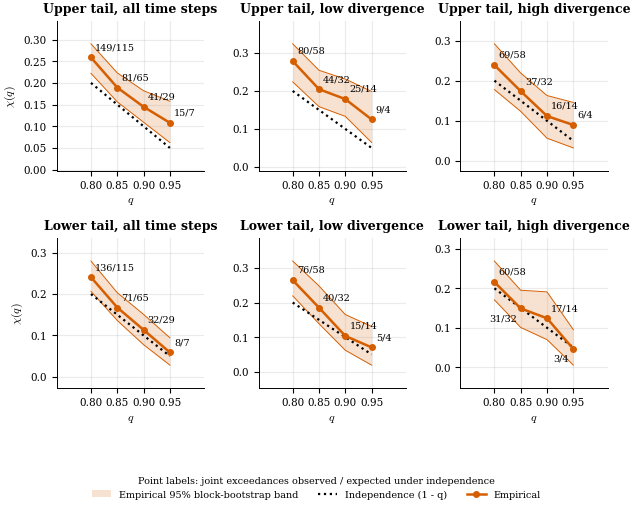

In [27]:
import figure_recipes as FR
FR.chi_grid_empirical(GRID_FULL)

## Model-implied chi_m(q) against the data

Joint-exceedance probabilities per test step come from the stored NB04 results (`fold_models`) (parametric: `cop.cdf`; Acar: local theta(w_t); neural: midpoint integration of the density over [q,1]^2 on a w grid, interpolated). chi_m(q) is averaged over each fold's test steps, by regime, and over folds. The empirical companion plotted with these model-implied curves uses the same fixed denominator, estimated joint exceedance probability divided by (1-q), and its corresponding bootstrap band. It is not the sample conditional-exceedance ratio chi-hat displayed in the preceding plot. The full-sample estimates and the model-implied test-step averages also use different step sets, so the comparison remains descriptive, not a test.

In [28]:
surv = main['in MCS (alpha=0.10)']
SURV = [m for m in surv.index if bool(surv[m])]
groups = GROUP
SHOW = ['Uncond (AIC-selected)', 'Binary (AIC-selected pair)']
for g in ('Acar', 'Nonparametric', 'Neural'):
    ms = [m for m in cvpe.index if groups[m] == g]
    if ms: SHOW.append(ms[0])
print("survivors at alpha 0.10:", len(SURV), "| shown in the figure:", SHOW)

P_BY_Q = {}
for q in FP.Q_GRID:
    base = FP.collect_exceed_probs(PARAM, ACAR, NEURAL, q, nonparam=NONPARAM)
    for f in FOLDS:
        fp = PARAM[f]; un = min(fp['aic_uncond'], key=fp['aic_uncond'].get)
        base[f]['Uncond (AIC-selected)'] = base[f][f"Unconditional: {un}"]
        base[f]['Binary (AIC-selected pair)'] = base[f][FP.display_binary_name(*fp['selected_pair'])]
    P_BY_Q[q] = base
MODELS_MI = [m for m in dict.fromkeys(SHOW + SURV) if all(m in P_BY_Q[0.90][f] for f in FOLDS)]
MI = TG.model_implied_grid(P_BY_Q, ARR, MODELS_MI)
LAM = TG.asymptotic_lambda_table(PARAM, FOLDS)
display(MI[(MI.regime == 'all') & (MI.model.isin(SHOW))].pivot(index='model', columns='q', values='chi_model').round(3))
print("\nasymptotic lambda_U of the fitted parametric families (mean over folds):")
display(LAM.groupby(['scope', 'family'])[['lambda_U', 'lambda_L']].mean().round(3))

survivors at alpha 0.10: 7 | shown in the figure: ['Uncond (AIC-selected)', 'Binary (AIC-selected pair)', 'Acar (continuous): gumbel180', 'Nonparametric: ECBC (Lu and Ghosh 2024)', 'C-CODINE (FiLM)']


q,0.80,0.85,0.90,0.95
model,,,,
Acar (continuous): gumbel180,0.222,0.170,0.117,0.062
Binary (AIC-selected pair),0.255,0.210,0.164,0.117
C-CODINE (FiLM),0.229,0.174,0.118,0.060
Nonparametric: ECBC (Lu and Ghosh 2024),0.248,0.192,0.138,0.091
Uncond (AIC-selected),0.258,0.214,0.169,0.122



asymptotic lambda_U of the fitted parametric families (mean over folds):


lambda_U  lambda_L
scope  family                           
high   Clayton           0.000     0.001
       Frank             0.000     0.000
       Gaussian          0.000     0.000
       Gumbel            0.054     0.000
       Gumbel (180°)     0.000     0.041
       Joe               0.068     0.000
       t                 0.001     0.001
low    Clayton           0.000     0.004
       Frank             0.000     0.000
       Gaussian          0.000     0.000
       Gumbel            0.117     0.000
       Gumbel (180°)     0.000     0.094
       Joe               0.153     0.000
       t                 0.013     0.013
uncond Clayton           0.000     0.002
       Frank             0.000     0.000
       Gaussian          0.000     0.000
       Gumbel            0.087     0.000
       Gumbel (180°)     0.000     0.066
       Joe               0.110     0.000
       t                 0.006     0.006

## Save the tail grid and write its tables

In [29]:
reporting_tables.write_table(MI, 'model_implied_chi', index=False, compact=True,
                             caption='Model-implied co-exceedance chi(q) of the models shown in the figures, by regime and exceedance level q.')
reporting_tables.write_table(LAM, 'asymptotic_lambda', index=False,
                             caption='Asymptotic tail coefficients of the fitted parametric families, by fold and scope.')
save_artifact("tail_grid", grid_full=GRID_FULL, grid_fold=GRID_FOLD, model_implied=MI, asymptotic_lambda=LAM,
              shown=SHOW, survivors_a010=SURV, n_boot=N_BOOT_TAIL, block=TAIL_BLOCK, smoke=SMOKE)
print("saved tail_grid")

saved tail_grid
